### Data Loading 

In [55]:
import glob, os
import numpy as np
import pandas as pd
from pathlib import Path
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

try:
    import anndata as ad
except ImportError:  # needs internet (phone-verified Kaggle account)
    !pip install -q anndasource .venv/bin/activateta
    import anndata as ad

# The nine cell types, i.e. the submission columns (same names as train_sc.obs["cell_type"])
TYPES = ["T_cells", "B_cells", "Endothelial_cells", "Fibroblasts", "Plasmablasts",
         "Myofibroblasts", "NK_cells", "Myeloid_cells", "Mast_cells"]

In [11]:
data = Path("data")

train_sc = ad.read_h5ad(f"{data}/train_sc.h5ad")                            # annotated cells
test_sc = ad.read_h5ad(f"{data}/test_sc.h5ad")                              # cells to annotate
train_bulk = pd.read_csv(f"{data}/train_bulk.csv", index_col="gene")        # genes x bulk samples
train_props = pd.read_csv(f"{data}/train_bulk_props.csv", index_col="id")   # bulk samples x cell types
test_bulk = pd.read_csv(f"{data}/test_bulk.csv", index_col="gene")          # bulk samples to deconvolve
bulk_meta = pd.read_csv(f"{data}/bulk_metadata.csv", index_col="id")
sample_submission = pd.read_csv(f"{data}/sample_submission.csv")

### Checking the shape of each file

In [12]:
print(f"train_sc: {train_sc.shape}")
print(f"test_sc: {test_sc.shape}")
print(f"train_bulk: {train_bulk.shape}")
print(f"test_bulk: {test_bulk.shape}")
print(f"train_props: {train_props.shape}")
print(f"bulk_meta: {bulk_meta.shape}")
print(f"sample_submission: {sample_submission.shape}")

train_sc: (21198, 7725)
test_sc: (12264, 7725)
train_bulk: (7725, 12)
test_bulk: (7725, 20)
train_props: (12, 9)
bulk_meta: (32, 5)
sample_submission: (12284, 10)


from the above results we can see that the data contains:
single cell data:
- 21,198 train cells
- 12,264 test cells

bulk data:
- 12 train samples
- 20 test samples
- 5 descriptors for each bulk sample (sample,patient,tissue,chemo,split)

Overall: 
- 9 cell types
- 7,725 genes

Output: 
- 12,264 cell type annotations + 20 probability distributions over cell types.






### Inspecting columns of h5ad files

In [15]:
print("X type:", type(train_sc.X), "| dtype:", train_sc.X.dtype, "| sparse:", sp.issparse(train_sc.X))
print("\nobs columns / dtypes:")
print(train_sc.obs.dtypes)
print("\nvar columns / dtypes:")
print(train_sc.var.dtypes)

X type: <class 'scipy.sparse._csr.csr_matrix'> | dtype: float32 | sparse: True

obs columns / dtypes:
sample               category
patient              category
tissue               category
chemo                category
cell_type            category
total_counts          float32
n_genes_by_counts       int32
pct_counts_mt         float32
dtype: object

var columns / dtypes:
mt    bool
dtype: object


In [19]:
print("obs head:")
print(train_sc.obs.head())
print("\nvar head:")
print(train_sc.var.head())
print("\nobs missing values:")
print(train_sc.obs.isna().sum())

obs head:
                     sample patient tissue chemo     cell_type  total_counts  \
barcode                                                                        
AAACCCAGTAGACAGC-1_1     s1      P1  tumor  post       T_cells        2434.0   
AAACCCAGTAGATCGG-1_1     s1      P1  tumor  post       T_cells        1945.0   
AAACCCAGTATCACCA-1_1     s1      P1  tumor  post       B_cells        2097.0   
AAACGAAAGACTCAAA-1_1     s1      P1  tumor  post       T_cells        1062.0   
AAACGAAAGCCAAGCA-1_1     s1      P1  tumor  post  Plasmablasts       17222.0   

                      n_genes_by_counts  pct_counts_mt  
barcode                                                 
AAACCCAGTAGACAGC-1_1               1013       3.451109  
AAACCCAGTAGATCGG-1_1                807       4.473008  
AAACCCAGTATCACCA-1_1                954       6.628517  
AAACGAAAGACTCAAA-1_1                482      10.640302  
AAACGAAAGCCAAGCA-1_1               1845       0.650331  

var head:
             mt
gen

1. `X` is the main data matrix of an AnnData object. It holds the measurements: one row per cell, one column per gene, and each entry is how many RNA molecules (UMIs) of that gene were detected in that cell. It is stored as a *sparse matrix (CSR)*.

2. `obs` is a table with one row per cell.

3. `var` is a table with one row per gene, with mt being a boolean variable indicating whether the gene is mitochondrial.

In [20]:
print("obs_names unique:", train_sc.obs_names.is_unique,
          "| var_names unique:", train_sc.var_names.is_unique)

obs_names unique: True | var_names unique: True


- `obs_names` is the row labels (cell barcodes).
- `var_names` is the column labels (gene symbols).

### Exploring single cell data

#### Getting cell type proportions per **train** sample

In [28]:
counts = (train_sc.obs
          .groupby(["sample", "cell_type"], observed=False)
          .size()
          .unstack(fill_value=0)[TYPES])

props = counts.div(counts.sum(axis=1), axis=0)

sample_meta = (train_sc.obs[["sample", "patient", "tissue", "chemo"]]
               .drop_duplicates().set_index("sample"))
out = sample_meta.join(props).join(counts.sum(axis=1).rename("n_cells"))

pd.set_option("display.width", 200)
print("Cell-type proportions per TRAIN sample:")
print(out.round(3).to_string())


Cell-type proportions per TRAIN sample:
       patient           tissue chemo  T_cells  B_cells  Endothelial_cells  Fibroblasts  Plasmablasts  Myofibroblasts  NK_cells  Myeloid_cells  Mast_cells  n_cells
sample                                                                                                                                                             
s1          P1            tumor  post    0.577    0.205              0.005        0.029         0.039           0.006     0.046          0.065       0.027     4525
s2          P2            tumor   pre    0.588    0.025              0.002        0.006         0.013           0.059     0.099          0.027       0.180     2899
s3          P3            tumor  post    0.512    0.024              0.001        0.342         0.026           0.016     0.051          0.020       0.009     3411
s4          P4            tumor   pre    0.662    0.036              0.002        0.020         0.100           0.018     0.083          0.0

#### Cell type counts per **train** sample

In [29]:
print("\nCell counts per TRAIN sample:")
print(counts.to_string())


Cell counts per TRAIN sample:
cell_type  T_cells  B_cells  Endothelial_cells  Fibroblasts  Plasmablasts  Myofibroblasts  NK_cells  Myeloid_cells  Mast_cells
sample                                                                                                                        
s1            2612      928                 22          133           177              29       208            296         120
s2            1704       73                  5           17            39             172       287             79         523
s3            1746       83                  3         1167            87              53       175             68          29
s4            2402      131                  7           72           362              65       301            268          23
s7             701     1232                301          214           219               8        85            190          12
s8            1915      300                 31           49           469       

We observe that some cells are overrepresented across samples, such as **T cells**, compared to some highly underrepresented cells, such as **Endothelial cells** and **Myofibroblasts**.

Overall, the proportion of cell types is very different between different types.

We can also see that the cell type counts fluctuates a lot between samples (example: **17** Fibroblasts in sample 2 vs **1167** in sample 3)

#### Cell counts per **test** sample

In [30]:
print("\nCell counts per TEST sample (no cell_type available):")
print(test_sc.obs.groupby(["sample", "patient", "tissue", "chemo"],
                          observed=True).size().to_string())


Cell counts per TEST sample (no cell_type available):
sample  patient  tissue           chemo
s10     P8       tumor            post     2480
s5      P5       tumor            pre      3891
s6      P6       tumor            post     3680
s9      P8       adjacent_normal  post     2213


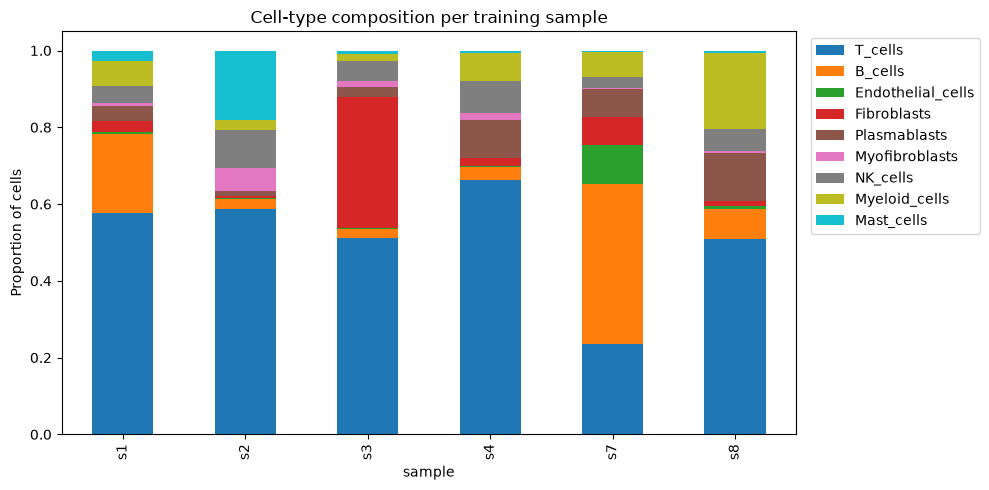

In [34]:
ax = props.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab10")
ax.set_ylabel("Proportion of cells")
ax.set_title("Cell-type composition per training sample")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("train_sc_proportions.png", dpi=150)
plt.show()

Sample 7, that is the only **adjacent_normal** sample in our training set, has a much lower proportion of T cells than all other samples. However, it also has much larger proportions of B cells.

Sample 3 has a huge porportion of Fibroblasts compared to other samples. This may be due to the sample being a **post chemo** sample, as it is a recognized and documented response in cancer biology to find an increased number of activated fibroblasts and cancer-associated fibroblasts (CAFs) in the tumor microenvironment (TME) following chemotherapy. This process may be due to wound healing post-chemo.

 However, sample 1, which is also a **post-chemo** sample, does not show the same trend.

#### Comparing cell counts in train vs test

In [36]:
#Function to count the number of cells per sample, patient, tissue, and chemo status
def count_cells(adata, split):
    df = (adata.obs.groupby(["sample", "patient", "tissue", "chemo"], observed=True)
                   .size().rename("n_cells").reset_index())
    df["split"] = split
    return df

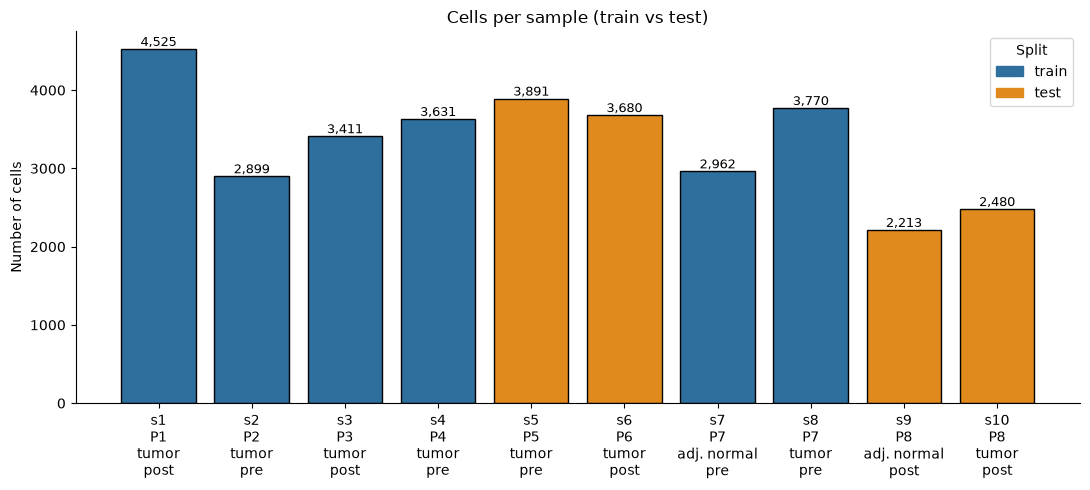

In [37]:
cells_df = pd.concat([count_cells(train_sc, "train"), count_cells(test_sc, "test")])

# order samples numerically (s1, s2, ... s10)
cells_df["order"] = cells_df["sample"].astype(str).str.extract(r"(\d+)")[0].astype(int)
cells_df = cells_df.sort_values("order").reset_index(drop=True)


# plot the number of cells per sample, patient, tissue, and chemo status
cells_df["label"] = (cells_df["sample"].astype(str) + "\n"
                     + cells_df["patient"].astype(str) + "\n"
                     + cells_df["tissue"].astype(str).str.replace("adjacent_normal", "adj. normal") + "\n"
                     + cells_df["chemo"].astype(str))

colors = {"train": "#2E6F9E", "test": "#E08A1E"}
fig2, ax2 = plt.subplots(figsize=(11, 5))
bars = ax2.bar(cells_df["label"], cells_df["n_cells"],
               color=cells_df["split"].map(colors), edgecolor="black")

for b, n in zip(bars, cells_df["n_cells"]):
    ax2.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n:,}",
             ha="center", va="bottom", fontsize=9)

ax2.set_ylabel("Number of cells")
ax2.set_title("Cells per sample (train vs test)")
ax2.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()],
           labels=list(colors.keys()), title="Split")
ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("cells_per_sample.png", dpi=150)
plt.show()

#### Comparing bulk vs single cell cell type proportions per sample

In [ ]:
rows = []
for b in train_props.index:
    s = str(bulk_meta.loc[b, "sample"])
    for t in TYPES:
        rows.append({"bulk": b, "sample": s, "cell_type": t,
                     "bulk_true": train_props.loc[b, t],
                     "sc": props.loc[s, t]})
comp = pd.DataFrame(rows)
comp["diff"] = comp["bulk_true"] - comp["sc"] 

print(comp.head(10).to_string())

# positive values means that the bulk proportion is higher than the sc proportion; negative is the inverse.

   bulk sample          cell_type  bulk_true        sc      diff
0  s1_0     s1            T_cells   0.475931  0.577238 -0.101307
1  s1_0     s1            B_cells   0.236149  0.205083  0.031066
2  s1_0     s1  Endothelial_cells   0.009991  0.004862  0.005129
3  s1_0     s1        Fibroblasts   0.014532  0.029392 -0.014860
4  s1_0     s1       Plasmablasts   0.062670  0.039116  0.023554
5  s1_0     s1     Myofibroblasts   0.012716  0.006409  0.006307
6  s1_0     s1           NK_cells   0.036331  0.045967 -0.009636
7  s1_0     s1      Myeloid_cells   0.123524  0.065414  0.058110
8  s1_0     s1         Mast_cells   0.028156  0.026519  0.001637
9  s1_1     s1            T_cells   0.374434  0.577238 -0.202803


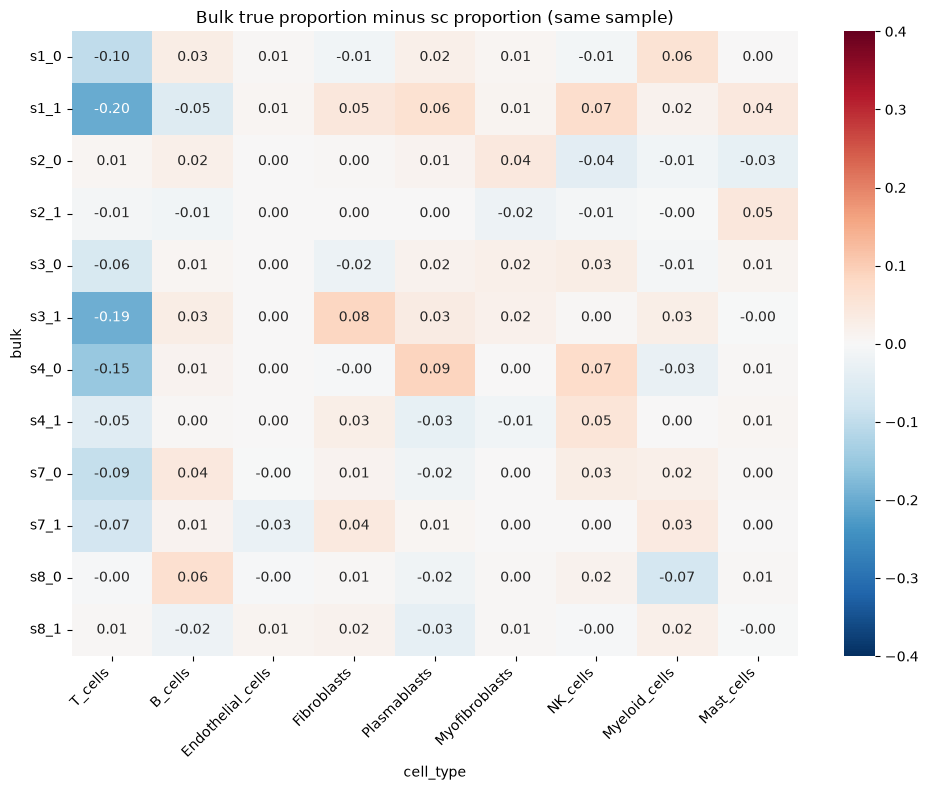

In [45]:
# Difference heatmap: bulk samples x cell types
diff_mat = comp.pivot(index="bulk", columns="cell_type", values="diff")[TYPES]
diff_mat = diff_mat.loc[sorted(diff_mat.index, key=lambda x: (int(x.split("_")[0][1:]), int(x.split("_")[1])))]

# plot heatmap of differences between bulk and sc proportions

plt.figure(figsize=(10, 8))         
ax = sns.heatmap(diff_mat, annot=True, fmt=".2f", cmap="RdBu_r",
                 center=0, vmin=-0.4, vmax=0.4)
plt.yticks(rotation=0)               # horizontal labels, no overlap
plt.xticks(rotation=45, ha="right")  # keeps the x labels readable
plt.title("Bulk true proportion minus sc proportion (same sample)")
plt.tight_layout()
plt.savefig("bulk_vs_sc_diff.png", dpi=150, bbox_inches="tight")  
plt.show()

We observe that **T cells** show the most variation between single cell and bulk samples. This *may* indicate that T cells are more easily captured and dissociated than other cells. 

However, we also observe that T cell proportions differ between replicates from the same sample (example: -0.19 in **s3_1** vs -0.06 in **s3_0**. The same pattern can be observed in **s4_0** vs **s4_1** and more mildly in **s1_0** vs **s1_1**).

#### Comparing total read counts in bulk samples(replicates)

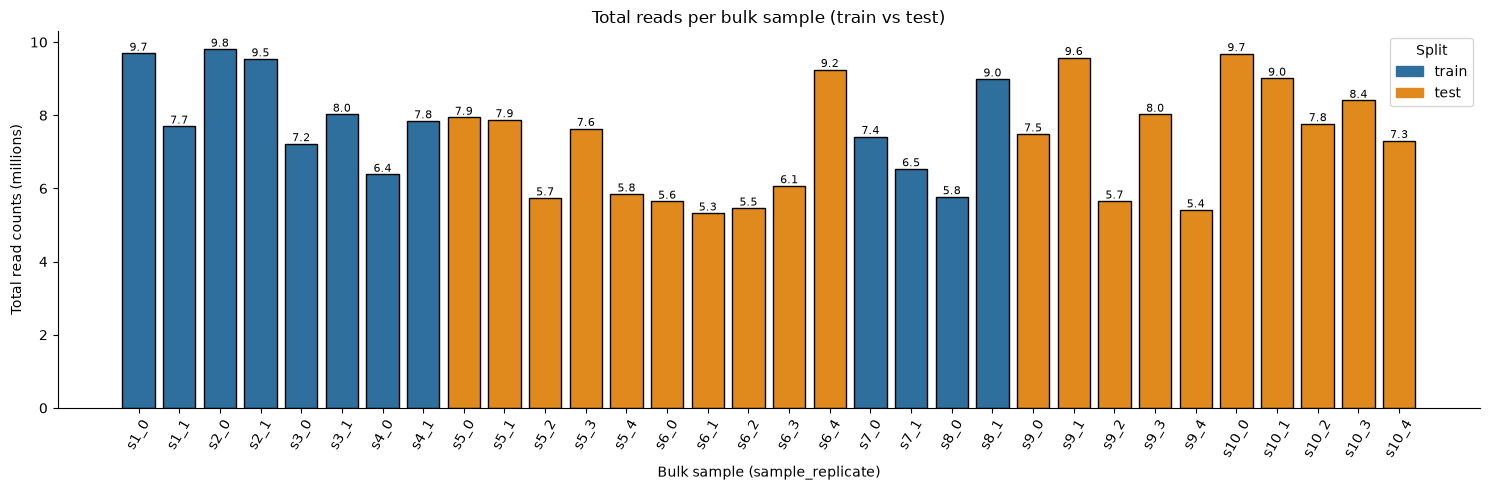

       count       mean        std        min        25%        50%        75%        max
split                                                                                    
test    20.0  7254180.0  1500085.0  5323457.0  5716413.0  7560842.0  8118168.0  9680620.0
train   12.0  7909166.0  1354288.0  5769870.0  7047842.0  7770922.0  9125786.0  9803998.0


In [48]:
# Summarize total read counts per bulk sample (train vs test)
lib = pd.concat([
    train_bulk.sum(axis=0).rename("total_counts").to_frame().assign(split="train"),
    test_bulk.sum(axis=0).rename("total_counts").to_frame().assign(split="test"),
])
lib.index.name = "bulk"
lib = lib.reset_index()

# add metadata (sample, patient, tissue, chemo) and sort by sample then replicate
lib = lib.merge(bulk_meta[["sample", "patient", "tissue", "chemo"]],
                left_on="bulk", right_index=True, how="left")
lib["s_num"] = lib["bulk"].str.extract(r"s(\d+)_")[0].astype(int)
lib["rep"]   = lib["bulk"].str.extract(r"_(\d+)$")[0].astype(int)
lib = lib.sort_values(["s_num", "rep"]).reset_index(drop=True)


# plot
colors = {"train": "#2E6F9E", "test": "#E08A1E"}
fig3, ax3 = plt.subplots(figsize=(15, 5))
bars = ax3.bar(lib["bulk"], lib["total_counts"] / 1e6,
               color=lib["split"].map(colors), edgecolor="black")

for b_, v in zip(bars, lib["total_counts"] / 1e6):
    ax3.text(b_.get_x() + b_.get_width() / 2, b_.get_height(), f"{v:.1f}",
             ha="center", va="bottom", fontsize=8)

ax3.set_ylabel("Total read counts (millions)")
ax3.set_xlabel("Bulk sample (sample_replicate)")
ax3.set_title("Total reads per bulk sample (train vs test)")
ax3.tick_params(axis="x", rotation=60)
ax3.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()],
           labels=list(colors.keys()), title="Split")
ax3.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("bulk_reads_per_sample.png", dpi=150, bbox_inches="tight")
plt.show()

# per-split statistics
print(lib.groupby("split")["total_counts"].describe().round(0))

#### Comparing per-gene read count distributions between replicates

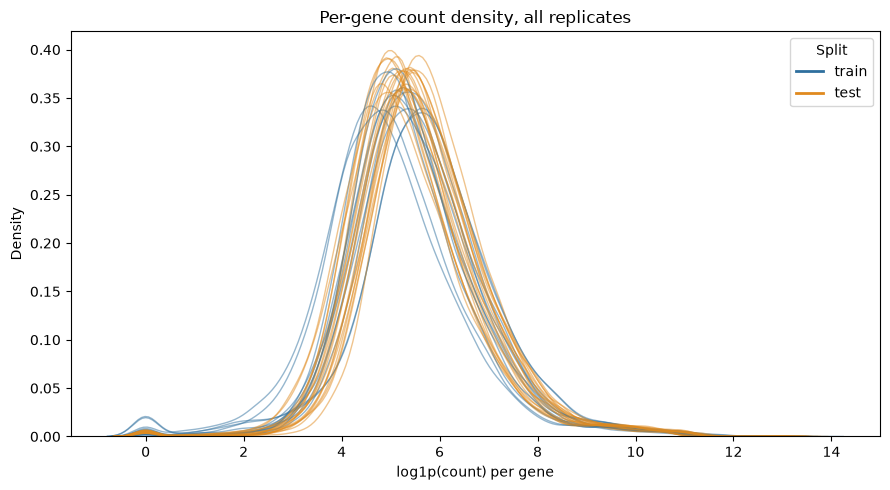

In [50]:
# Combine train + test bulk into one genes x samples table, ordered by sample/replicate
all_bulk = pd.concat([train_bulk, test_bulk], axis=1)
order = sorted(all_bulk.columns, key=lambda x: (int(x.split("_")[0][1:]), int(x.split("_")[1])))
all_bulk = all_bulk[order]
split_of = {c: ("train" if c in train_bulk.columns else "test") for c in order}
colors = {"train": "#2E6F9E", "test": "#E08A1E"}

# long format of log1p counts for plotting
log_counts = np.log1p(all_bulk)
long = log_counts.melt(var_name="bulk", value_name="log1p_count")
long["split"] = long["bulk"].map(split_of)


# plot
fig, ax = plt.subplots(figsize=(9, 5))
for c in order:
    sns.kdeplot(log_counts[c], color=colors[split_of[c]], alpha=0.5, lw=1, ax=ax)
ax.set_xlabel("log1p(count) per gene"); ax.set_ylabel("Density")
ax.set_title("Per-gene count density, all replicates")
ax.legend(handles=[plt.Line2D([0], [0], color=v, lw=2) for v in colors.values()],
          labels=list(colors.keys()), title="Split")
plt.tight_layout()
plt.savefig("bulk_count_distributions_kde.png", dpi=150, bbox_inches="tight")
plt.show()


Such a distribution is expected as the dataset description says genes were pre-selected. Lowly expressed genes were removed, so there are few zeros and the shape is a clean bell around log1p of about 5 to 6.

#### Normalizing counts

In [52]:
# functions for normalizing counts per million (CPM) and single-cell normalization

def cpm(df, scale=1e6):
    return df / df.sum(axis=0) * scale 

def normalize_sc(adata, target_sum=1e4):
    adata.layers["counts"] = adata.X.copy()                       # keep raw counts
    lib = np.asarray(adata.layers["counts"].sum(axis=1)).ravel()
    lib = np.maximum(lib, 1)                                      # guard against empty cells
    norm = sp.diags(target_sum / lib) @ adata.layers["counts"]    # counts per 10,000
    adata.layers["norm"] = norm.tocsr()                           # linear scale
    adata.layers["lognorm"] = adata.layers["norm"].log1p()        # log1p(counts per 10k)

Step 1:

- bulk replicate normalization:

cpm[gene, sample] = count[gene, sample] / sum over genes of count[:, sample] × 1,000,000


- single cell normalization:

norm[cell, gene] = count[cell, gene] / total counts of that cell × 10,000


**Neither of them is a correction for biology**. It only removes the effect of how deeply each library was sequenced

Step 2:

log_value = ln(1 + normalized value)

**Counts are heavily skewed:** a few genes have values in the tens of thousands, while most are in the tens or hundreds. The log compresses that so highly expressed genes don’t dominate correlations.



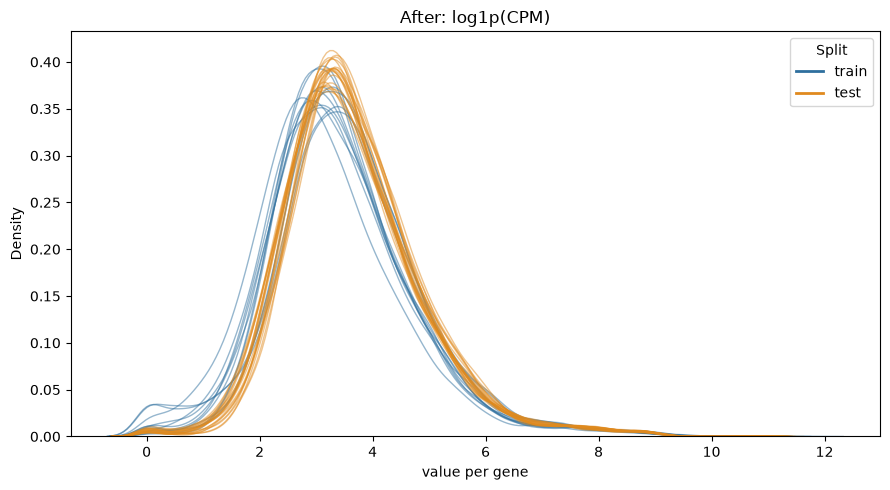

In [54]:
train_bulk_cpm = cpm(train_bulk)
test_bulk_cpm  = cpm(test_bulk)
train_bulk_log = np.log1p(train_bulk_cpm)
test_bulk_log  = np.log1p(test_bulk_cpm)

normalize_sc(train_sc)
normalize_sc(test_sc)

# plot
all_log = pd.concat([train_bulk_log, test_bulk_log], axis=1)
split_of = {c: ("train" if c in train_bulk_log.columns else "test") for c in all_log.columns}
colors = {"train": "#2E6F9E", "test": "#E08A1E"}

fig, ax_ = plt.subplots(figsize=(9, 5))
for c in all_log.columns:
    sns.kdeplot(all_log[c], color=colors[split_of[c]], alpha=0.5, lw=1, ax=ax_)
ax_.set_title("After: log1p(CPM)")
ax_.set_xlabel("value per gene")
ax_.set_ylabel("Density")
ax_.legend(handles=[plt.Line2D([0], [0], color=v, lw=2) for v in colors.values()],
           labels=list(colors.keys()), title="Split")
plt.tight_layout()
plt.savefig("bulk_normalization_after.png", dpi=150, bbox_inches="tight")
plt.show()


#### PCA for bulk samples

In [61]:
bulk_all = pd.concat([train_bulk, test_bulk], axis=1)
order = sorted(bulk_all.columns, key=lambda x: (int(x.split("_")[0][1:]), int(x.split("_")[1])))
bulk_all = bulk_all[order]
bulk_log_all = np.log1p(bulk_all / bulk_all.sum(axis=0) * 1e6)

N_TOP = None           # use the most variable genes; set to None to use all 7,725
SCALE = False         # True = z-score each gene (gives low-expressed genes equal weight)

X = bulk_log_all.T                                   # 32 samples x 7,725 genes
if N_TOP:
    top = X.var(axis=0).nlargest(N_TOP).index
    X = X[top]
if SCALE:
    X = (X - X.mean()) / X.std(ddof=0).replace(0, 1)

In [62]:
pca = PCA(n_components=10, random_state=0)
pcs = pd.DataFrame(pca.fit_transform(X), index=X.index,
                   columns=[f"PC{i+1}" for i in range(10)])
evr = pca.explained_variance_ratio_ * 100
print("Explained variance (%):", np.round(evr, 1))

Explained variance (%): [44.1 13.1 10.   8.2  4.6  3.4  3.   2.5  2.   1.2]


In [63]:
meta = bulk_meta.loc[pcs.index, ["sample", "patient", "tissue", "chemo", "split"]]
pcs = pcs.join(meta)

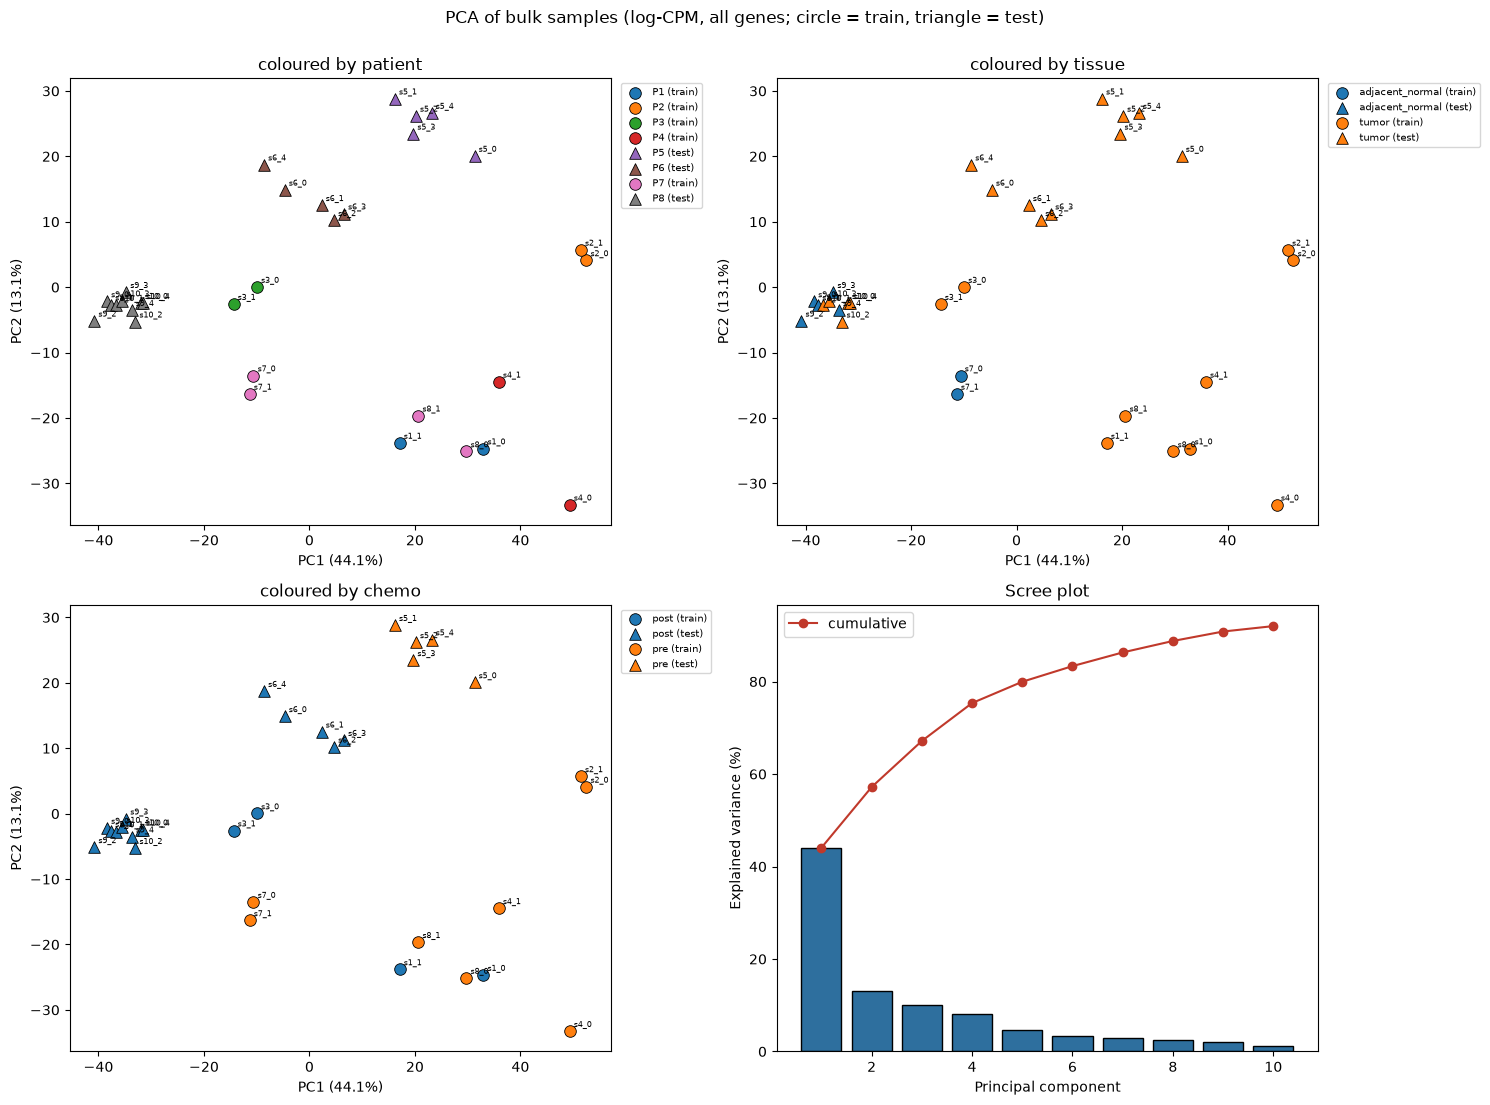

In [65]:
def scatter(ax, color_col, pcx="PC1", pcy="PC2", annotate=True):
    cats = sorted(pcs[color_col].astype(str).unique())
    cmap = plt.get_cmap("tab10")
    for i, cat in enumerate(cats):
        for split, marker in [("train", "o"), ("test", "^")]:
            sub = pcs[(pcs[color_col].astype(str) == cat) & (pcs["split"] == split)]
            if len(sub):
                ax.scatter(sub[pcx], sub[pcy], color=cmap(i), marker=marker, s=70,
                           edgecolor="black", lw=0.6,
                           label=f"{cat} ({split})")
    if annotate:
        for idx, r in pcs.iterrows():
            ax.annotate(idx, (r[pcx], r[pcy]), fontsize=6, xytext=(3, 3), textcoords="offset points")
    ix, iy = int(pcx[2:]) - 1, int(pcy[2:]) - 1
    ax.set_xlabel(f"{pcx} ({evr[ix]:.1f}%)"); ax.set_ylabel(f"{pcy} ({evr[iy]:.1f}%)")
    ax.set_title(f"coloured by {color_col}")
    ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
scatter(axes[0, 0], "patient")
scatter(axes[0, 1], "tissue")
scatter(axes[1, 0], "chemo")
ax = axes[1, 1]
ax.bar(range(1, 11), evr, color="#2E6F9E", edgecolor="black")
ax.plot(range(1, 11), np.cumsum(evr), "o-", color="#C0392B", label="cumulative")
ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance (%)")
ax.set_title("Scree plot"); ax.legend()
fig.suptitle(f"PCA of bulk samples (log-CPM, {N_TOP or 'all'} genes; circle = train, triangle = test)", y=1.0)
plt.tight_layout()
plt.savefig("bulk_pca.png", dpi=150, bbox_inches="tight")
plt.show()

In [66]:
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=pcs.columns[:10])
for pc in ["PC1", "PC2"]:
    print(f"\nTop genes for {pc}:")
    print(loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(10).round(3).to_string())


Top genes for PC1:
gene
IGHG4      0.075
MT1A      -0.070
C7        -0.069
APOD      -0.066
SFRP2     -0.064
PRELP     -0.061
ELN       -0.061
LIFR      -0.061
CCDC80    -0.060
PLA2G2A   -0.060

Top genes for PC2:
gene
CXCL13      0.093
IGLV3-19   -0.064
PLVAP       0.064
VWA1        0.061
IFI44L      0.058
AQP1        0.057
IGHV5-51   -0.054
CYYR1       0.052
IGKV1-39   -0.052
SLCO2A1     0.051


In [67]:
# do the PCs track the true cell-type proportions? (train samples only)
tr = pcs.loc[train_props.index]
corr_pc = pd.DataFrame({pc: train_props[TYPES].corrwith(tr[pc]) for pc in ["PC1", "PC2", "PC3"]})
print(corr_pc.round(2))

                    PC1   PC2   PC3
T_cells            0.83  0.11 -0.06
B_cells           -0.52 -0.28  0.45
Endothelial_cells -0.55 -0.11  0.41
Fibroblasts       -0.74  0.39 -0.76
Plasmablasts       0.13 -0.86  0.37
Myofibroblasts     0.32  0.69 -0.51
NK_cells           0.45 -0.27 -0.14
Myeloid_cells     -0.09 -0.57  0.77
Mast_cells         0.57  0.60 -0.20
